# 05 — Field front-end segmentation and presence/absence estimation

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*  
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri)

## 1. Objective

This notebook applies the **frozen detector produced by notebook 04** to the real pond recordings.

The pipeline is:

**pond WAV → consecutive 30 s blocks → species-band FIR filter → 10 ms STE →
12-point moving average → endpoint detection → original unfiltered candidate segment →
20 m-FCC → frozen GMM scores → species hypothesis → likelihood ratio →
class-specific threshold → accepted detection → presence/absence per field sample**

### What is explicitly specified by the paper

`[PAPER]`

- field audio is divided into **consecutive 30-second blocks**;
- a band-pass **FIR** filter is used before segmentation;
- filter cut-offs are selected from the species frequency ranges;
- the filter is used **only for segmentation**;
- classification uses the corresponding segment from the **original unfiltered audio**;
- short-time energy (STE) uses **10 ms consecutive, non-overlapping frames**;
- the STE sequence is smoothed with a moving average of **MA = 12**;
- endpoint detection requires **3 consecutive values over the threshold** to start a segment;
- after a start, **3 consecutive values below the threshold** end it;
- detected fragments are transformed to the same cepstral representation used for GMM training;
- one accepted call is sufficient to mark a species as present in a field sample.

The species frequency ranges used below are the ranges reported in Table 1.

### Important unresolved parameter: endpoint constant C

The paper says the endpoint threshold depends on an empirical constant `C`, but does **not report its
value**. In addition, the printed threshold equation is ambiguous when applied directly to negative dB
STE values.

`[REPLICATION DECISION]`

This notebook implements a conventional dB interpolation form:

\[
threshold_{dB}
=
mean(STE_{dB})
+
\frac{max(STE_{dB})-mean(STE_{dB})}{C}.
\]

`C = 2.0` is provided only as a **provisional starting value**. It is not attributed to the paper.
A diagnostic section is included before the full scan. The full 22+ hour scan is disabled by default
until that front-end behavior has been inspected.

### Detector limitation

Notebook 04 produced usable frozen models for:

`f01, f02, f03, f04, f05, f06, f07, f08, f10`.

`f09` cannot be estimated from the recovered labelled corpus. It must therefore remain
**unknown / not modelled**, not silently converted to biological absence.

In [6]:
from pathlib import Path
import json
import os
import re
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

from scipy.fft import dct
from scipy.signal import fftconvolve, firwin

try:
    import librosa
except ImportError as exc:
    raise ImportError(
        "Notebook 05 needs librosa because notebook 02 reconstructed the 40-filter "
        "bank with librosa. Install the repository requirements first."
    ) from exc

pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 160)
pd.set_option("display.max_columns", 80)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = REPO_ROOT / "data" / "processed"

CALIBRATION_DIR = (
    PROCESSED_DIR / "likelihood_ratio_calibration_fixed"
)
MODEL_DIR = (
    REPO_ROOT / "models" / "gmm_fixed_calibration"
)

THRESHOLDS_PATH = CALIBRATION_DIR / "thresholds.csv"
DETECTOR_METADATA_PATH = CALIBRATION_DIR / "detector_metadata.json"

FIELD_RESULTS_DIR = (
    PROCESSED_DIR / "field_presence_absence"
)
FIELD_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for path in (THRESHOLDS_PATH, DETECTOR_METADATA_PATH):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run the fixed-split notebook 04 first."
        )

print("Repository root :", REPO_ROOT)
print("Detector models :", MODEL_DIR)
print("Detector config :", CALIBRATION_DIR)
print("Field outputs   :", FIELD_RESULTS_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
Detector models : C:\Users\sofia\Projects\PUCE\frog-presence-replication\models\gmm_fixed_calibration
Detector config : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\likelihood_ratio_calibration_fixed
Field outputs   : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\field_presence_absence


## 2. Load the frozen detector from notebook 04

Notebook 05 does not fit or modify any GMM.

The model files and thresholds must correspond to the same frozen detector calibrated in notebook 04.

In [7]:
thresholds = pd.read_csv(THRESHOLDS_PATH)

with open(
    DETECTOR_METADATA_PATH,
    "r",
    encoding="utf-8",
) as f:
    detector_metadata = json.load(f)

USABLE_CODES = tuple(detector_metadata["classes"])
THRESHOLD_BY_CODE = (
    thresholds
    .set_index("code")["threshold"]
    .to_dict()
)

MODELS = {}

for code in USABLE_CODES:
    model_path = MODEL_DIR / f"{code}_gmm.joblib"

    if not model_path.exists():
        raise FileNotFoundError(
            f"Missing frozen model {model_path}. "
            "Re-run notebook 04 before field inference."
        )

    MODELS[code] = joblib.load(model_path)

assert set(MODELS) == set(USABLE_CODES)
assert set(THRESHOLD_BY_CODE) == set(USABLE_CODES)

for code, model in MODELS.items():
    assert model.covariance_type == "diag"

print("Loaded classes:", USABLE_CODES)
display(
    thresholds[
        ["code", "species", "threshold", "fpr", "tpr", "auroc"]
    ].round(4)
)

Loaded classes: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')


,code,species,threshold,fpr,tpr,auroc
0,f01,Boana alfaroi,22.1950,0.0000,1.0000,1.0000
1,f02,Dendropsophus bifurcus,23.8904,0.0435,0.8000,0.9522
2,f03,Boana cinerascens,26.4991,0.0115,1.0000,0.9994
3,f04,Pristimantis conspicillatus,22.1101,0.0000,1.0000,1.0000
4,f05,Leptodactylus discodactylus,31.3620,0.0439,0.7941,0.9774
5,f06,Osteocephalus fuscifacies,16.6902,0.0000,1.0000,1.0000
6,f07,Boana lanciformis,24.6576,0.0109,1.0000,0.9988
7,f08,Rhinella margaritifera,37.8728,0.0000,1.0000,1.0000
8,f10,Engystomops petersi,26.1655,0.0431,1.0000,0.9963


## 3. Locate Dataset 2: pond recordings

The repository README keeps the large audio collections outside Git and points to them through `.env`.

Because the exact environment-variable name is installation-specific, this notebook:

1. reads `.env` if present;
2. looks for common Dataset-2 / pond variable names;
3. if necessary, searches environment keys containing `POND`, `DATASET2` or `DATASET_2`;
4. allows an explicit `POND_ROOT_OVERRIDE`.

If auto-detection fails, edit **one variable only** in the cell below.

In [8]:
import seaborn as sns
from dotenv import load_dotenv

# Configuration: plotting style, the dataset locations read from .env, and the display
# options used by every table below. Nothing here inspects the data.

# One global style, so no figure below has to repeat grid and spine settings.
sns.set_theme(style="ticks")


# The audio lives outside the repository, in a different place on every machine, so the
# three locations are read from a local .env file instead of being written into the code.
load_dotenv()


def dataset_dir(variable: str) -> Path:
    """Read one dataset location from the environment.

    Args:
        variable (str): Name of the variable defined in .env, e.g. "PONDS_CALL_DIR".

    Returns:
        Path: The configured directory.

    Raises:
        RuntimeError: If the variable is missing, so the failure explains itself rather
            than surfacing as a bare KeyError.
    """
    value = os.environ.get(variable)
    if not value:
        raise RuntimeError(
            f"{variable} is not set. Copy .env.example to .env and fill in the paths "
            "to your local copies of the three collections."
        )
    return Path(value)


MENDELEY_CALL_DIR = dataset_dir("MENDELEY_CALL_DIR")
PONDS_CALL_DIR = dataset_dir("PONDS_CALL_DIR")
SPECIES_CALL_DIR = dataset_dir("SPECIES_CALL_DIR")


# Verify that the dataset directories exist before running the analysis. Only the folder
# name is printed: the full path is personal to whoever is running the notebook.
for path in (MENDELEY_CALL_DIR, PONDS_CALL_DIR, SPECIES_CALL_DIR):
    print(f"{'OK ' if path.is_dir() else 'MISSING'}  {path.name}")

print(f"\nsoundfile {sf.__version__} (libsndfile {sf.__libsndfile_version__})")


# Configure pandas display options for easier visualization of summary tables
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 120)

OK   data
OK   pond-recordings
OK   species-calls

soundfile 0.14.0 (libsndfile 1.2.2)


In [9]:
# Edit only this value if the pond dataset is not found automatically.
# Example:
# POND_ROOT_OVERRIDE = Path(r"D:/frog_data/pond_recordings")
POND_ROOT_OVERRIDE = PONDS_CALL_DIR


def load_simple_dotenv(path):
    if not path.exists():
        return

    for raw_line in path.read_text(
        encoding="utf-8",
        errors="ignore",
    ).splitlines():
        line = raw_line.strip()

        if (
            not line
            or line.startswith("#")
            or "=" not in line
        ):
            continue

        key, value = line.split("=", 1)
        key = key.strip()
        value = value.strip().strip('"').strip("'")

        if key and value and key not in os.environ:
            os.environ[key] = value


load_simple_dotenv(REPO_ROOT / ".env")


def resolve_pond_root():
    if POND_ROOT_OVERRIDE is not None:
        return Path(POND_ROOT_OVERRIDE).expanduser()

    preferred_keys = [
        "DATASET2_PATH",
        "DATASET_2_PATH",
        "DATASET2_ROOT",
        "DATASET_2_ROOT",
        "POND_DATA_PATH",
        "POND_ROOT",
        "POND_RECORDINGS_PATH",
    ]

    for key in preferred_keys:
        value = os.getenv(key)
        if value:
            candidate = Path(value).expanduser()
            if candidate.exists():
                print("Using environment variable:", key)
                return candidate

    for key, value in os.environ.items():
        key_upper = key.upper()

        if (
            "POND" in key_upper
            or "DATASET2" in key_upper
            or "DATASET_2" in key_upper
        ):
            try:
                candidate = Path(value).expanduser()
            except TypeError:
                continue

            if candidate.exists():
                print("Using detected environment variable:", key)
                return candidate

    return None


POND_ROOT = resolve_pond_root()

if POND_ROOT is None or not POND_ROOT.exists():
    raise FileNotFoundError(
        "Dataset 2 could not be located. Set POND_ROOT_OVERRIDE above "
        "to the root containing the P1/P2 pond WAV recordings."
    )

# Defensive check: Dataset 2 must be the pond-recordings collection, not species references.
if "SPECIES_CALL_DIR" in globals():
    try:
        if Path(POND_ROOT).resolve() == Path(SPECIES_CALL_DIR).resolve():
            raise RuntimeError(
                "POND_ROOT points to SPECIES_CALL_DIR. "
                "Use PONDS_CALL_DIR for notebook 05."
            )
    except OSError:
        pass

print("Pond root:", POND_ROOT)

Pond root: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\pond-recordings


## 4. Inventory the field WAV files

`[PAPER]` The testing corpus consists of **141 nominally 10-minute samples**, digitized to WAV at
48 kHz.

The recovered data audit found duration discrepancies relative to the nominal 23.5 hours, so this
notebook does not force every file to exactly 600 seconds.

A WAV is marked *eligible* when it is:

- readable;
- 48 kHz;
- PCM WAV.

The inventory is printed before inference. If the eligible count is not 141, the notebook warns
rather than silently changing the data.

In [10]:
def infer_pond(path):
    text = " ".join(part.lower() for part in path.parts)

    p1_patterns = [
        r"\bp1\b",
        r"pond\s*1",
        r"pond1",
        r"poza\s*1",
        r"poza1",
    ]
    p2_patterns = [
        r"\bp2\b",
        r"pond\s*2",
        r"pond2",
        r"poza\s*2",
        r"poza2",
    ]

    if any(re.search(p, text) for p in p1_patterns):
        return "P1"

    if any(re.search(p, text) for p in p2_patterns):
        return "P2"

    return "unknown"


wav_paths = sorted({
    *POND_ROOT.rglob("*.wav"),
    *POND_ROOT.rglob("*.WAV"),
})

inventory_rows = []

for path in wav_paths:
    try:
        info = sf.info(path)

        inventory_rows.append({
            "path": str(path),
            "relative_path": str(path.relative_to(POND_ROOT)),
            "sample_id": path.stem,
            "pond": infer_pond(path),
            "samplerate": info.samplerate,
            "channels": info.channels,
            "frames": info.frames,
            "duration_seconds": info.duration,
            "format": info.format,
            "subtype": info.subtype,
            "readable": True,
            "error": None,
        })

    except Exception as exc:
        inventory_rows.append({
            "path": str(path),
            "relative_path": str(path.relative_to(POND_ROOT)),
            "sample_id": path.stem,
            "pond": infer_pond(path),
            "samplerate": np.nan,
            "channels": np.nan,
            "frames": np.nan,
            "duration_seconds": np.nan,
            "format": None,
            "subtype": None,
            "readable": False,
            "error": repr(exc),
        })


field_inventory = pd.DataFrame(inventory_rows)

if field_inventory.empty:
    raise FileNotFoundError(
        f"No WAV files were found below {POND_ROOT}"
    )

field_inventory["eligible"] = (
    field_inventory["readable"]
    & (field_inventory["samplerate"] == 48_000)
    & (field_inventory["format"] == "WAV")
    & field_inventory["subtype"].fillna("").str.startswith("PCM")
)

display(
    field_inventory[
        [
            "relative_path",
            "pond",
            "samplerate",
            "channels",
            "duration_seconds",
            "subtype",
            "eligible",
        ]
    ].head(20).round(3)
)

eligible_inventory = (
    field_inventory[field_inventory["eligible"]]
    .copy()
    .reset_index(drop=True)
)

print("WAV files found :", len(field_inventory))
print("Eligible WAVs   :", len(eligible_inventory))
print(
    "Eligible hours  :",
    round(eligible_inventory["duration_seconds"].sum() / 3600, 3),
)

if len(eligible_inventory) != 141:
    warnings.warn(
        f"The paper reports 141 field samples, but this installation "
        f"contains {len(eligible_inventory)} eligible WAV files."
    )

field_inventory.to_csv(
    FIELD_RESULTS_DIR / "field_audio_inventory.csv",
    index=False,
)

,relative_path,pond,samplerate,channels,duration_seconds,subtype,eligible
0,qcaz-cc106\A\._cc106A-Poza1_SP1.wav,P1,NaN,NaN,NaN,NaN,False
1,qcaz-cc106\A\._cc106A-Poza1_SP3.wav,P1,NaN,NaN,NaN,NaN,False
2,qcaz-cc106\A\._cc106A-Poza2_SP2.wav,P2,NaN,NaN,NaN,NaN,False
3,qcaz-cc106\A\._cc106A-Poza2_SP2A.wav,P2,NaN,NaN,NaN,NaN,False
4,qcaz-cc106\A\._cc106A-Poza2_SP2B.wav,P2,NaN,NaN,NaN,NaN,False
5,qcaz-cc106\A\._cc106A.wav,unknown,NaN,NaN,NaN,NaN,False
6,qcaz-cc106\A\._cc106A_SP1.wav,unknown,NaN,NaN,NaN,NaN,False
7,qcaz-cc106\A\cc106A-Poza1_SP1.wav,P1,44100.0,1.0,633.905,GSM610,False
8,qcaz-cc106\A\cc106A-Poza1_SP3.wav,P1,44100.0,1.0,598.886,GSM610,False
9,qcaz-cc106\A\cc106A-Poza2_SP2.wav,P2,44100.0,1.0,496.718,GSM610,False


WAV files found : 1680
Eligible WAVs   : 546
Eligible hours  : 51.373


C:\Users\sofia\AppData\Local\Temp\ipykernel_36148\851724807.py:113: UserWarning: The paper reports 141 field samples, but this installation contains 546 eligible WAV files.
  warnings.warn(


## 5. Species-specific segmentation bands

The following frequency intervals come directly from Table 1 of the paper.

The front-end filter is used **only to find candidate endpoints**. Once an interval is detected, the
same time interval is taken from the original unfiltered block for feature extraction and GMM
classification.

In [11]:
PAPER_FREQUENCY_BANDS_HZ = {
    "f01": (1660, 3100),
    "f02": (2300, 3390),
    "f03": (1300, 1530),
    "f04": (1630, 3900),
    "f05": (1680, 3260),
    "f06": (1000, 2500),
    "f07": (500, 2720),
    "f08": (800, 1700),
    "f09": (5660, 7500),
    "f10": (430, 3140),
}

SEGMENTATION_BANDS_HZ = {
    code: PAPER_FREQUENCY_BANDS_HZ[code]
    for code in USABLE_CODES
}

band_table = pd.DataFrame([
    {
        "code": code,
        "low_hz": low,
        "high_hz": high,
    }
    for code, (low, high) in SEGMENTATION_BANDS_HZ.items()
])

display(band_table)

,code,low_hz,high_hz
0,f01,1660,3100
1,f02,2300,3390
2,f03,1300,1530
3,f04,1630,3900
4,f05,1680,3260
5,f06,1000,2500
6,f07,500,2720
7,f08,800,1700
8,f10,430,3140


## 6. Front-end segmentation configuration

### Values stated by the paper

- block size: `30 s`
- STE frame: `10 ms`
- STE overlap: `0%`
- moving average: `12`
- endpoint persistence: `3` frames

### Values not stated by the paper

The paper does not report the FIR order or the empirical constant `C`.

`[REPLICATION DECISION]`

- FIR: 513-tap linear-phase filter;
- filtering: same-length FFT convolution, because only endpoint localization is required;
- endpoint threshold interpolation: mean-to-maximum dB formula;
- initial `C = 2.0`.

The full field scan is deliberately disabled until the diagnostic section is inspected.

In [12]:
BLOCK_SECONDS = 30.0
STE_FRAME_SECONDS = 0.010
STE_MA_LENGTH = 12
ENDPOINT_RUN = 3

FIR_NUMTAPS = 513

# Empirical segmentation constants.
# They can later be tuned per species if field inspection justifies it.
ENDPOINT_C_BY_CODE = {
    code: 2.0
    for code in USABLE_CODES
}

# Feature extraction must remain compatible with notebook 02.
FEATURE_FRAME_SECONDS = 0.020
FEATURE_OVERLAP = 0.75
PRE_EMPHASIS = 0.99
NFFT = 1024
N_FILTERS = 40
N_CEPSTRA = 20
FILTERBANK_FMIN = 500.0
FILTERBANK_FMAX = 20_000.0

RUN_FULL_FIELD_SCAN = False
MAX_FIELD_FILES = None

print("Full field scan enabled:", RUN_FULL_FIELD_SCAN)

Full field scan enabled: False


## 7. FIR band-pass filtering and short-time energy

STE follows Equation 1 conceptually: sum of squared samples inside every non-overlapping 10 ms frame.

Stereo files, if any, are converted to mono by channel averaging before processing.

In [13]:
def to_mono(audio):
    audio = np.asarray(audio, dtype=np.float64)

    if audio.ndim == 1:
        return audio

    if audio.ndim == 2:
        return audio.mean(axis=1)

    raise ValueError(
        f"Unsupported audio shape: {audio.shape}"
    )


def bandpass_for_segmentation(
    audio,
    sr,
    low_hz,
    high_hz,
    numtaps=FIR_NUMTAPS,
):
    nyquist = sr / 2

    if not (0 < low_hz < high_hz < nyquist):
        raise ValueError(
            f"Invalid band ({low_hz}, {high_hz}) "
            f"for sr={sr}."
        )

    taps = firwin(
        numtaps=numtaps,
        cutoff=[low_hz, high_hz],
        pass_zero=False,
        fs=sr,
    )

    # Linear-phase FIR, aligned back to the original block with mode='same'.
    return fftconvolve(
        audio,
        taps,
        mode="same",
    )


def short_time_energy(
    audio,
    sr,
    frame_seconds=STE_FRAME_SECONDS,
):
    frame_samples = int(round(sr * frame_seconds))

    if frame_samples <= 0:
        raise ValueError("STE frame size must be positive.")

    n_frames = len(audio) // frame_samples

    if n_frames == 0:
        return np.empty(0), frame_samples

    trimmed = audio[:n_frames * frame_samples]

    frames = trimmed.reshape(
        n_frames,
        frame_samples,
    )

    energy = np.sum(
        frames * frames,
        axis=1,
    )

    return energy, frame_samples


def moving_average_same(
    values,
    length=STE_MA_LENGTH,
):
    values = np.asarray(values, dtype=float)

    if len(values) == 0:
        return values.copy()

    kernel = np.ones(length, dtype=float) / length

    return np.convolve(
        values,
        kernel,
        mode="same",
    )


def energy_to_db(energy):
    energy = np.asarray(energy, dtype=float)

    floor = np.finfo(float).tiny

    return 10.0 * np.log10(
        np.maximum(energy, floor)
    )

## 8. Endpoint threshold and 3-frame endpoint detector

The paper leaves `C` empirical. The implementation below keeps it explicit.

Increasing `C` moves the threshold closer to the mean STE level and therefore generally makes the
front-end **more sensitive**. Decreasing it toward 1 moves the threshold toward the maximum and makes
segmentation more selective.

In [14]:
def endpoint_threshold_db(
    ste_db,
    C,
):
    ste_db = np.asarray(ste_db, dtype=float)

    if len(ste_db) == 0:
        return np.nan

    if C <= 0:
        raise ValueError("C must be positive.")

    mean_db = float(np.mean(ste_db))
    max_db = float(np.max(ste_db))

    return (
        mean_db
        + (max_db - mean_db) / C
    )


def find_endpoint_runs(
    ste_db,
    threshold_db,
    run_length=ENDPOINT_RUN,
):
    ste_db = np.asarray(ste_db, dtype=float)

    segments = []

    in_segment = False
    start_idx = None
    i = 0

    while i <= len(ste_db) - run_length:

        if not in_segment:
            if np.all(
                ste_db[i:i + run_length]
                > threshold_db
            ):
                start_idx = i
                in_segment = True

                # Continue after the confirming run.
                i += run_length
                continue

        else:
            if np.all(
                ste_db[i:i + run_length]
                < threshold_db
            ):
                # End at the first frame of the confirming below-threshold run.
                end_idx = i

                if end_idx > start_idx:
                    segments.append(
                        (start_idx, end_idx)
                    )

                start_idx = None
                in_segment = False

                i += run_length
                continue

        i += 1

    # If activity continues to the end of the 30-s block,
    # retain the remaining interval as one candidate segment.
    if in_segment and start_idx is not None:
        segments.append(
            (start_idx, len(ste_db))
        )

    return segments

## 9. Segment one 30-second block for one species band

The timestamps returned by this function are relative to the **unfiltered 30-second block**.

In [15]:
def segment_block_for_band(
    original_block,
    sr,
    code,
    C=None,
):
    low_hz, high_hz = SEGMENTATION_BANDS_HZ[code]

    if C is None:
        C = ENDPOINT_C_BY_CODE[code]

    filtered = bandpass_for_segmentation(
        original_block,
        sr,
        low_hz,
        high_hz,
    )

    ste, ste_frame_samples = short_time_energy(
        filtered,
        sr,
    )

    ste_smooth = moving_average_same(
        ste,
        STE_MA_LENGTH,
    )

    ste_db = energy_to_db(
        ste_smooth,
    )

    threshold_db = endpoint_threshold_db(
        ste_db,
        C=C,
    )

    endpoint_frames = find_endpoint_runs(
        ste_db,
        threshold_db,
    )

    segments = []

    for start_frame, end_frame in endpoint_frames:
        start_sample = (
            start_frame
            * ste_frame_samples
        )
        end_sample = min(
            len(original_block),
            end_frame * ste_frame_samples,
        )

        if end_sample <= start_sample:
            continue

        segments.append({
            "segmenter_code": code,
            "start_frame_10ms": start_frame,
            "end_frame_10ms": end_frame,
            "start_sample": start_sample,
            "end_sample": end_sample,
            "start_seconds": start_sample / sr,
            "end_seconds": end_sample / sr,
            "duration_seconds": (
                end_sample - start_sample
            ) / sr,
        })

    diagnostics = {
        "filtered": filtered,
        "ste": ste,
        "ste_smooth": ste_smooth,
        "ste_db": ste_db,
        "threshold_db": threshold_db,
        "C": C,
    }

    return segments, diagnostics

## 10. Reproduce the notebook-02 20 m-FCC front end

The GMMs cannot receive a different feature representation from the one used during training.

The previous preprocessing notebook documented the following implementation choices:

- pre-emphasis coefficient `0.99`;
- 20 ms frames;
- 75% overlap, therefore a 5 ms hop;
- Hamming window;
- `NFFT = 1024`;
- 40 triangular filters;
- recovered filter-bank approximation between 500 Hz and 20 kHz using a mel-layout implementation;
- log filter energies;
- DCT;
- first 20 coefficients.

The paper specifies the general procedure but does not provide the exact numerical construction of its
modified filter bank or the DFT size. Those limitations therefore remain inherited by notebook 05.

In [16]:
def pre_emphasise(
    audio,
    coefficient=PRE_EMPHASIS,
):
    audio = np.asarray(
        audio,
        dtype=np.float64,
    )

    if len(audio) == 0:
        return audio.copy()

    emphasized = np.empty_like(audio)
    emphasized[0] = audio[0]

    emphasized[1:] = (
        audio[1:]
        - coefficient * audio[:-1]
    )

    return emphasized


def frame_signal_for_features(
    audio,
    sr,
):
    frame_length = int(
        round(FEATURE_FRAME_SECONDS * sr)
    )

    hop_seconds = (
        FEATURE_FRAME_SECONDS
        * (1.0 - FEATURE_OVERLAP)
    )

    hop_length = int(
        round(hop_seconds * sr)
    )

    if (
        frame_length <= 0
        or hop_length <= 0
    ):
        raise ValueError(
            "Invalid feature frame configuration."
        )

    if len(audio) < frame_length:
        return np.empty(
            (0, frame_length),
            dtype=np.float64,
        )

    n_frames = (
        1
        + (len(audio) - frame_length)
        // hop_length
    )

    starts = (
        np.arange(n_frames)
        * hop_length
    )

    frames = np.stack([
        audio[start:start + frame_length]
        for start in starts
    ])

    return frames


def mfcc20_replication(
    audio,
    sr,
):
    audio = to_mono(audio)

    emphasized = pre_emphasise(
        audio,
        PRE_EMPHASIS,
    )

    frames = frame_signal_for_features(
        emphasized,
        sr,
    )

    if len(frames) == 0:
        return np.empty(
            (0, N_CEPSTRA),
            dtype=np.float64,
        )

    window = np.hamming(
        frames.shape[1]
    )

    windowed = (
        frames
        * window[None, :]
    )

    spectrum = np.fft.rfft(
        windowed,
        n=NFFT,
        axis=1,
    )

    power = (
        np.abs(spectrum) ** 2
    ) / NFFT

    fmax = min(
        FILTERBANK_FMAX,
        sr / 2 - 1e-6,
    )

    filterbank = librosa.filters.mel(
        sr=sr,
        n_fft=NFFT,
        n_mels=N_FILTERS,
        fmin=FILTERBANK_FMIN,
        fmax=fmax,
        htk=False,
        norm=None,
    )

    filter_energies = (
        power
        @ filterbank.T
    )

    filter_energies = np.maximum(
        filter_energies,
        np.finfo(float).eps,
    )

    log_energies = np.log(
        filter_energies
    )

    cepstra = dct(
        log_energies,
        type=2,
        axis=1,
        norm="ortho",
    )

    return cepstra[:, :N_CEPSTRA]

## 11. Frozen GMM verification interface

This is the same detector logic frozen in notebook 04.

For a candidate segment:

1. score all species GMMs;
2. choose the highest-scoring model as the hypothesis;
3. subtract the median score of all other models;
4. accept only when that LLR reaches the class-specific threshold.

In [17]:
def model_scores(
    X_segment,
):
    return {
        code: float(
            model.score_samples(
                X_segment
            ).mean()
        )
        for code, model in MODELS.items()
    }


def verify_features(
    X_segment,
):
    if (
        X_segment.ndim != 2
        or X_segment.shape[1] != 20
    ):
        raise ValueError(
            f"Expected feature matrix (*, 20), got {X_segment.shape}."
        )

    if len(X_segment) == 0:
        return None

    scores = model_scores(
        X_segment,
    )

    hypothesis = max(
        scores,
        key=scores.get,
    )

    alternative_median = float(
        np.median([
            score
            for code, score in scores.items()
            if code != hypothesis
        ])
    )

    llr = float(
        scores[hypothesis]
        - alternative_median
    )

    threshold = float(
        THRESHOLD_BY_CODE[hypothesis]
    )

    return {
        "hypothesis": hypothesis,
        "hypothesis_score": float(
            scores[hypothesis]
        ),
        "alternative_median": alternative_median,
        "llr": llr,
        "threshold": threshold,
        "accepted": bool(
            llr >= threshold
        ),
    }

## 12. Diagnostic: inspect the first 30-second block before scanning 22+ hours

This section is deliberately placed before the full run because the empirical segmentation constant
`C` is not supplied by the paper.

The first eligible field file is loaded, the first 30 seconds are segmented for each usable species
band, and the number/duration of candidate segments is shown.

This is where `ENDPOINT_C_BY_CODE` should be adjusted if the front end is clearly segmenting almost
everything or almost nothing.

In [18]:
if eligible_inventory.empty:
    raise RuntimeError(
        "No eligible 48-kHz PCM field WAVs are available."
    )

diagnostic_path = Path(
    eligible_inventory.iloc[0]["path"]
)

diagnostic_audio, diagnostic_sr = sf.read(
    diagnostic_path,
    always_2d=False,
)

diagnostic_audio = to_mono(
    diagnostic_audio
)

diagnostic_block = diagnostic_audio[
    :int(round(BLOCK_SECONDS * diagnostic_sr))
]

diagnostic_rows = []
diagnostic_by_code = {}

for code in USABLE_CODES:
    segs, diag = segment_block_for_band(
        diagnostic_block,
        diagnostic_sr,
        code,
    )

    diagnostic_by_code[code] = (
        segs,
        diag,
    )

    diagnostic_rows.append({
        "code": code,
        "C": diag["C"],
        "threshold_db": diag["threshold_db"],
        "n_segments": len(segs),
        "total_candidate_seconds": sum(
            s["duration_seconds"]
            for s in segs
        ),
        "max_segment_seconds": max(
            [
                s["duration_seconds"]
                for s in segs
            ],
            default=0.0,
        ),
    })

segmentation_diagnostic = pd.DataFrame(
    diagnostic_rows
)

print("Diagnostic file:", diagnostic_path)
print("Sample rate     :", diagnostic_sr)

display(
    segmentation_diagnostic.round(4)
)

Diagnostic file: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\pond-recordings\qcaz-cc126\A\cc126A- poza1_SP1.wav
Sample rate     : 48000


,code,C,threshold_db,n_segments,total_candidate_seconds,max_segment_seconds
0,f01,2.0,-14.7720,13,3.07,0.44
1,f02,2.0,-14.7693,13,3.01,0.43
2,f03,2.0,-17.9980,10,2.25,0.37
3,f04,2.0,-12.0309,11,2.02,0.44
4,f05,2.0,-14.3045,13,3.07,0.44
5,f06,2.0,-10.4384,11,2.43,0.36
6,f07,2.0,-8.0401,15,3.41,0.55
7,f08,2.0,-11.1784,10,2.34,0.37
8,f10,2.0,-5.9831,11,2.77,0.73


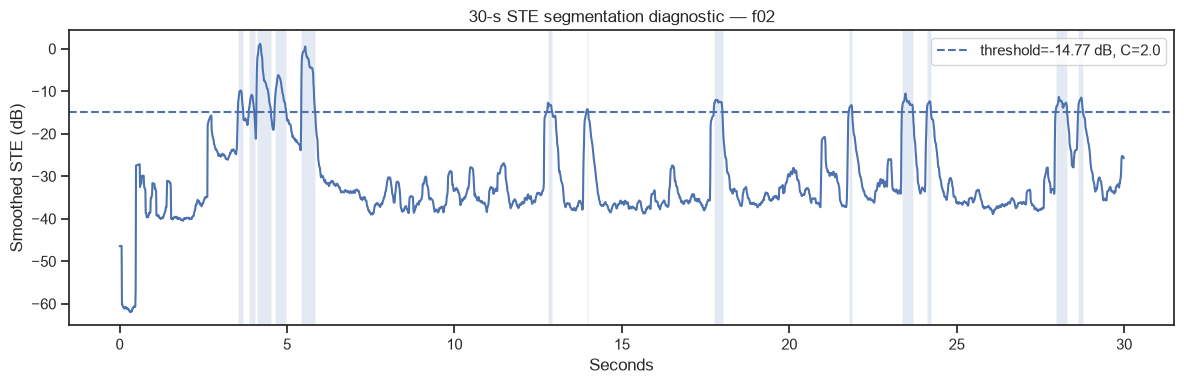

Detected candidate segments: 13


In [19]:
# Visual diagnostic for one representative species.
DIAGNOSTIC_CODE = "f02" if "f02" in USABLE_CODES else USABLE_CODES[0]

segments_demo, diag_demo = diagnostic_by_code[
    DIAGNOSTIC_CODE
]

time_db = (
    np.arange(len(diag_demo["ste_db"]))
    * STE_FRAME_SECONDS
)

fig, ax = plt.subplots(
    figsize=(12, 4)
)

ax.plot(
    time_db,
    diag_demo["ste_db"],
)

ax.axhline(
    diag_demo["threshold_db"],
    linestyle="--",
    label=(
        f"threshold={diag_demo['threshold_db']:.2f} dB, "
        f"C={diag_demo['C']}"
    ),
)

for segment in segments_demo:
    ax.axvspan(
        segment["start_seconds"],
        segment["end_seconds"],
        alpha=0.15,
    )

ax.set(
    title=f"30-s STE segmentation diagnostic — {DIAGNOSTIC_CODE}",
    xlabel="Seconds",
    ylabel="Smoothed STE (dB)",
)

ax.legend()
plt.tight_layout()
plt.show()

print(
    "Detected candidate segments:",
    len(segments_demo),
)

## 13. Process one complete 30-second block

Each species frequency band generates candidate endpoints.

The resulting candidate interval is always sliced from `original_block`, not from the band-pass signal,
before m-FCC extraction and classification.

In [20]:
def process_block(
    original_block,
    sr,
    sample_id,
    block_index,
    block_start_seconds,
):
    detection_rows = []
    candidate_rows = []

    for segmenter_code in USABLE_CODES:

        segments, diagnostics = (
            segment_block_for_band(
                original_block,
                sr,
                segmenter_code,
            )
        )

        for local_segment_index, segment in enumerate(segments):

            start_sample = segment["start_sample"]
            end_sample = segment["end_sample"]

            # Critical paper rule:
            # use ORIGINAL UNFILTERED audio for classification.
            candidate_audio = original_block[
                start_sample:end_sample
            ]

            X = mfcc20_replication(
                candidate_audio,
                sr,
            )

            candidate_id = (
                f"{sample_id}"
                f"_b{block_index:03d}"
                f"_{segmenter_code}"
                f"_s{local_segment_index:04d}"
            )

            base_row = {
                "sample_id": sample_id,
                "candidate_id": candidate_id,
                "block_index": block_index,
                "segmenter_code": segmenter_code,
                "block_start_seconds": block_start_seconds,
                "local_start_seconds": segment["start_seconds"],
                "local_end_seconds": segment["end_seconds"],
                "absolute_start_seconds": (
                    block_start_seconds
                    + segment["start_seconds"]
                ),
                "absolute_end_seconds": (
                    block_start_seconds
                    + segment["end_seconds"]
                ),
                "duration_seconds": segment["duration_seconds"],
                "n_feature_frames": len(X),
                "endpoint_C": diagnostics["C"],
                "endpoint_threshold_db": diagnostics["threshold_db"],
            }

            if len(X) == 0:
                candidate_rows.append({
                    **base_row,
                    "status": "too_short_for_features",
                })
                continue

            result = verify_features(
                X
            )

            candidate_rows.append({
                **base_row,
                "status": "scored",
            })

            detection_rows.append({
                **base_row,
                "hypothesis": result["hypothesis"],
                "hypothesis_score": result["hypothesis_score"],
                "alternative_median": result["alternative_median"],
                "llr": result["llr"],
                "threshold": result["threshold"],
                "accepted": result["accepted"],
            })

    return (
        pd.DataFrame(candidate_rows),
        pd.DataFrame(detection_rows),
    )

## 14. Smoke test the entire detector on the first 30 seconds

This runs the complete path:

**FIR → STE → endpoints → original segment → m-FCC → GMM → LLR → threshold**

before any multi-hour run is attempted.

In [21]:
smoke_candidates, smoke_detections = process_block(
    original_block=diagnostic_block,
    sr=diagnostic_sr,
    sample_id=diagnostic_path.stem,
    block_index=0,
    block_start_seconds=0.0,
)

print("Candidate intervals:", len(smoke_candidates))
print("Scored candidates  :", len(smoke_detections))

if not smoke_detections.empty:
    print(
        "Accepted detections:",
        int(smoke_detections["accepted"].sum()),
    )

    display(
        smoke_detections[
            [
                "segmenter_code",
                "absolute_start_seconds",
                "absolute_end_seconds",
                "duration_seconds",
                "hypothesis",
                "llr",
                "threshold",
                "accepted",
            ]
        ]
        .sort_values(
            [
                "absolute_start_seconds",
                "segmenter_code",
            ]
        )
        .head(50)
        .round(4)
    )
else:
    print("No candidate reached feature scoring.")

Candidate intervals: 107
Scored candidates  : 107
Accepted detections: 94


,segmenter_code,absolute_start_seconds,absolute_end_seconds,duration_seconds,hypothesis,llr,threshold,accepted
0,f01,2.63,2.75,0.12,f10,26.7298,26.1655,True
26,f03,2.63,2.75,0.12,f10,26.7298,26.1655,True
47,f05,2.63,2.75,0.12,f10,26.7298,26.1655,True
60,f06,2.63,2.75,0.12,f10,26.7298,26.1655,True
71,f07,2.63,2.75,0.12,f10,26.7298,26.1655,True
86,f08,2.63,2.75,0.12,f10,26.7298,26.1655,True
36,f04,2.68,2.75,0.07,f10,31.9512,26.1655,True
96,f10,3.52,3.71,0.19,f10,23.2324,26.1655,False
37,f04,3.53,3.80,0.27,f10,22.3306,26.1655,False
72,f07,3.53,3.71,0.18,f10,22.6365,26.1655,False


## 15. Process one complete field WAV

The paper describes each field sample as approximately ten minutes. The file is internally processed
as consecutive, non-overlapping 30-second blocks.

A final partial block, if present, is also processed rather than discarded because the recovered files
do not all have the exact nominal duration.

In [22]:
def process_field_file(
    path,
):
    path = Path(path)

    audio, sr = sf.read(
        path,
        always_2d=False,
    )

    audio = to_mono(
        audio
    )

    if sr != 48_000:
        raise ValueError(
            f"{path} has sr={sr}; expected 48000 Hz field audio."
        )

    block_samples = int(
        round(BLOCK_SECONDS * sr)
    )

    candidate_blocks = []
    detection_blocks = []

    n_blocks = int(
        np.ceil(
            len(audio)
            / block_samples
        )
    )

    for block_index in range(n_blocks):

        start_sample = (
            block_index
            * block_samples
        )

        end_sample = min(
            len(audio),
            start_sample + block_samples,
        )

        block = audio[
            start_sample:end_sample
        ]

        if len(block) < int(
            round(
                FEATURE_FRAME_SECONDS
                * sr
            )
        ):
            continue

        block_start_seconds = (
            start_sample / sr
        )

        candidates, detections = (
            process_block(
                original_block=block,
                sr=sr,
                sample_id=path.stem,
                block_index=block_index,
                block_start_seconds=block_start_seconds,
            )
        )

        if not candidates.empty:
            candidates["source_path"] = str(path)
            candidate_blocks.append(candidates)

        if not detections.empty:
            detections["source_path"] = str(path)
            detection_blocks.append(detections)

    all_candidates = (
        pd.concat(
            candidate_blocks,
            ignore_index=True,
        )
        if candidate_blocks
        else pd.DataFrame()
    )

    all_detections = (
        pd.concat(
            detection_blocks,
            ignore_index=True,
        )
        if detection_blocks
        else pd.DataFrame()
    )

    return (
        all_candidates,
        all_detections,
    )

## 16. Convert accepted detections into presence/absence

For the nine modelled species:

- `1` = at least one accepted detection anywhere in the field sample;
- `0` = no accepted detection.

For `f09`:

- `NA` = **not modelled**.

This distinction is important. `NA` must not be rewritten as zero, because zero would claim biological
absence when the actual problem is lack of a usable acoustic model.

In [23]:
PAPER_CLASS_ORDER = (
    "f01",
    "f02",
    "f03",
    "f04",
    "f05",
    "f06",
    "f07",
    "f08",
    "f09",
    "f10",
)


def presence_from_detections(
    sample_id,
    detections,
):
    accepted = (
        detections[
            detections["accepted"]
        ]
        if (
            not detections.empty
            and "accepted" in detections
        )
        else pd.DataFrame()
    )

    row = {
        "sample_id": sample_id,
    }

    for code in PAPER_CLASS_ORDER:
        column = f"presence_{code}"

        if code not in USABLE_CODES:
            row[column] = pd.NA
            continue

        if accepted.empty:
            row[column] = 0
        else:
            row[column] = int(
                (
                    accepted["hypothesis"]
                    == code
                ).any()
            )

    return row


smoke_presence = pd.DataFrame([
    presence_from_detections(
        diagnostic_path.stem,
        smoke_detections,
    )
])

display(smoke_presence)

,sample_id,presence_f01,presence_f02,presence_f03,presence_f04,presence_f05,presence_f06,presence_f07,presence_f08,presence_f09,presence_f10
0,cc126A- poza1_SP1,0,0,0,0,0,0,0,0,<NA>,1


## 17. Full field scan

**Do not turn this on merely because computers enjoy suffering.**

Before running the entire corpus, inspect:

- the segmentation diagnostic;
- number and duration of candidates;
- accepted detections in the smoke test;
- whether the provisional `C = 2.0` is obviously too selective or too permissive.

When satisfied, set:

```python
RUN_FULL_FIELD_SCAN = True
```

in Section 6 and run from there.

`MAX_FIELD_FILES` can be set to a small integer, such as `3`, for an intermediate integration test.

In [24]:
all_candidate_blocks = []
all_detection_blocks = []
presence_rows = []
file_run_rows = []

if RUN_FULL_FIELD_SCAN:

    files_to_process = (
        eligible_inventory
        if MAX_FIELD_FILES is None
        else eligible_inventory.head(MAX_FIELD_FILES)
    )

    for file_number, row in enumerate(
        files_to_process.itertuples(index=False),
        start=1,
    ):
        path = Path(row.path)

        print(
            f"[{file_number:03d}/{len(files_to_process):03d}] "
            f"{path.name}"
        )

        try:
            candidates, detections = process_field_file(
                path
            )

            if not candidates.empty:
                all_candidate_blocks.append(
                    candidates
                )

            if not detections.empty:
                all_detection_blocks.append(
                    detections
                )

            presence_rows.append(
                presence_from_detections(
                    path.stem,
                    detections,
                )
            )

            file_run_rows.append({
                "sample_id": path.stem,
                "source_path": str(path),
                "pond": row.pond,
                "duration_seconds": row.duration_seconds,
                "n_candidates": len(candidates),
                "n_scored": len(detections),
                "n_accepted": (
                    int(detections["accepted"].sum())
                    if not detections.empty
                    else 0
                ),
                "status": "ok",
                "error": None,
            })

        except Exception as exc:
            file_run_rows.append({
                "sample_id": path.stem,
                "source_path": str(path),
                "pond": row.pond,
                "duration_seconds": row.duration_seconds,
                "n_candidates": np.nan,
                "n_scored": np.nan,
                "n_accepted": np.nan,
                "status": "error",
                "error": repr(exc),
            })

            print("  ERROR:", repr(exc))

    field_candidates = (
        pd.concat(
            all_candidate_blocks,
            ignore_index=True,
        )
        if all_candidate_blocks
        else pd.DataFrame()
    )

    field_detections = (
        pd.concat(
            all_detection_blocks,
            ignore_index=True,
        )
        if all_detection_blocks
        else pd.DataFrame()
    )

    field_presence = pd.DataFrame(
        presence_rows
    )

    field_run_summary = pd.DataFrame(
        file_run_rows
    )

else:
    print(
        "Full scan skipped. "
        "Inspect the diagnostic and set RUN_FULL_FIELD_SCAN=True when ready."
    )

Full scan skipped. Inspect the diagnostic and set RUN_FULL_FIELD_SCAN=True when ready.


## 18. Summaries after the full run

In [25]:
if RUN_FULL_FIELD_SCAN:

    display(
        field_run_summary.head()
    )

    print(
        "Files processed successfully:",
        int(
            (
                field_run_summary["status"]
                == "ok"
            ).sum()
        ),
    )

    print(
        "Files with errors:",
        int(
            (
                field_run_summary["status"]
                == "error"
            ).sum()
        ),
    )

    if not field_detections.empty:

        accepted = field_detections[
            field_detections["accepted"]
        ]

        detection_summary = (
            accepted
            .groupby(
                "hypothesis",
                as_index=False,
            )
            .agg(
                accepted_detections=(
                    "candidate_id",
                    "size",
                ),
                samples_detected=(
                    "sample_id",
                    "nunique",
                ),
                median_llr=(
                    "llr",
                    "median",
                ),
                median_duration_seconds=(
                    "duration_seconds",
                    "median",
                ),
            )
        )

        display(
            detection_summary.round(4)
        )

    display(
        field_presence.head()
    )

## 19. Save field outputs

Raw candidate intervals and scored detections are retained so every presence decision can be audited
back to its time interval and segmentation band.

In [26]:
if RUN_FULL_FIELD_SCAN:

    field_run_summary.to_csv(
        FIELD_RESULTS_DIR / "field_run_summary.csv",
        index=False,
    )

    field_presence.to_csv(
        FIELD_RESULTS_DIR / "presence_absence.csv",
        index=False,
    )

    if not field_candidates.empty:
        field_candidates.to_csv(
            FIELD_RESULTS_DIR / "candidate_segments.csv",
            index=False,
        )

    if not field_detections.empty:
        field_detections.to_csv(
            FIELD_RESULTS_DIR / "segment_detections.csv",
            index=False,
        )

    run_metadata = {
        "block_seconds": BLOCK_SECONDS,
        "ste_frame_seconds": STE_FRAME_SECONDS,
        "ste_ma_length": STE_MA_LENGTH,
        "endpoint_run": ENDPOINT_RUN,
        "fir_numtaps": FIR_NUMTAPS,
        "endpoint_C_by_code": ENDPOINT_C_BY_CODE,
        "feature_frame_seconds": FEATURE_FRAME_SECONDS,
        "feature_overlap": FEATURE_OVERLAP,
        "pre_emphasis": PRE_EMPHASIS,
        "nfft": NFFT,
        "n_filters": N_FILTERS,
        "n_cepstra": N_CEPSTRA,
        "filterbank_fmin": FILTERBANK_FMIN,
        "filterbank_fmax": FILTERBANK_FMAX,
        "classes_modelled": list(USABLE_CODES),
        "f09_policy": "NA_not_modelled",
        "model_directory": str(MODEL_DIR),
        "thresholds_path": str(THRESHOLDS_PATH),
        "pond_root": str(POND_ROOT),
        "frequency_bands_hz": {
            code: list(band)
            for code, band in SEGMENTATION_BANDS_HZ.items()
        },
        "endpoint_threshold_note": (
            "C is not reported by the paper. This run uses the explicit "
            "replication threshold mean_db + (max_db - mean_db)/C."
        ),
    }

    with open(
        FIELD_RESULTS_DIR / "field_run_metadata.json",
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            run_metadata,
            f,
            indent=2,
        )

    print("Saved outputs:")
    for path in sorted(
        FIELD_RESULTS_DIR.iterdir()
    ):
        print(" ", path.name)

## 20. Presence/absence sanity checks

The checks below prevent the two most damaging bookkeeping errors:

1. a modelled species receiving values other than 0/1;
2. `f09`, which has no deployable model, being silently interpreted as absence.

In [27]:
if RUN_FULL_FIELD_SCAN:

    for code in USABLE_CODES:
        col = f"presence_{code}"

        assert set(
            field_presence[col]
            .dropna()
            .unique()
        ).issubset({0, 1})

    if "f09" not in USABLE_CODES:
        assert (
            field_presence["presence_f09"]
            .isna()
            .all()
        )

    assert (
        field_presence["sample_id"]
        .is_unique
    )

    print("Presence/absence sanity checks: OK")

## 21. Optional comparison with recovered partial field annotations

The earlier data audit found that some field species information can be recovered for part of the pond
corpus, but **an unmentioned species cannot be interpreted as absent**.

Therefore this notebook deliberately does **not** compute recall, precision, specificity or accuracy
from partial notes alone.

A later evaluation notebook may compare detections only where explicit positive/negative labels can
be justified, or use the paper's 18 fully manually labelled samples if their complete vectors become
available.

## 22. Conclusions and limitations

### What notebook 05 implements

- frozen detector loading from notebook 04;
- recursive inventory of Dataset 2 pond WAV files;
- species-specific frequency bands from Table 1;
- consecutive 30-second processing;
- band-pass FIR front-end;
- 10 ms non-overlapping STE;
- 12-value moving-average smoothing;
- 3-over / 3-under endpoint logic;
- extraction of candidate audio from the **original unfiltered block**;
- the same 20 m-FCC reconstruction used by the training pipeline;
- frozen GMM species identification;
- median-alternative likelihood ratio;
- frozen per-class threshold verification;
- one-detection-is-enough presence aggregation;
- explicit `NA` handling for unmodelled `f09`;
- auditable candidate, detection and presence tables.

### Remaining limitations

1. **Endpoint constant `C` is missing from the paper.** The current value is provisional and explicitly
   a replication decision.
2. **FIR order is not reported.** This notebook uses 513 taps.
3. **The exact modified filter-bank numerical definition is not published.** The implementation inherits
   notebook 02's documented approximation.
4. **`f09` is not modelled.** Presence/absence is therefore nine-class, with `f09 = NA`.
5. **The calibrated GMMs in notebook 04 reserve 20% of labelled calls**, because the field threshold
   fine-tuning material used by the original authors is incomplete in the recovered data.
6. **Partial field annotations are not complete absence labels**, so this notebook does not manufacture
   evaluation metrics from them.

### Next step

After the full scan is run successfully, the next notebook should focus on **field-result validation
and ecological summaries**, not additional model fitting:

**presence table → recoverable ground-truth comparison → sample/pond/month summaries →
paper-result comparison → limitations.**